Test the slab model with 2 islands. Fig.15 (e):
$$
\begin{align*}
&m_1=m_2=1\;,\;n_1=-n_2=1\\
&\delta_1=\delta_2 =0.5\\
&\iota'=3.6
\end{align*}
$$

In [1]:
import warnings
warnings.filterwarnings("ignore", category=SyntaxWarning)

import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
from fields.slab_bfield_two_pert import SlabBfieldTwoPert
from pyoculus.maps import ToroidalBfieldSection
from pyoculus.solvers import PoincarePlot, FixedPoint, Manifold
import matplotlib.pyplot as plt

#### Create the magnetic field:

In [2]:
field = SlabBfieldTwoPert(
    m1=1,
    n1=1,
    delta1=0.5,
    m2=1,
    n2=-1,
    delta2=0.5,
    iota_prime=3.6,
    x0=1.0,
)

xs1 = field.x0 + field.n1 / (field.iota_prime * field.m1)
xs2 = field.x0 + field.n2 / (field.iota_prime * field.m2)

print("The islands will be situated at x_s =", xs1, xs2)

The islands will be situated at x_s = 1.2777777777777777 0.7222222222222222


#### Create the map:

In [3]:
map = ToroidalBfieldSection(field, domain=[(0, 2), (0, 2*np.pi)])

#### Create Poincaré plot:

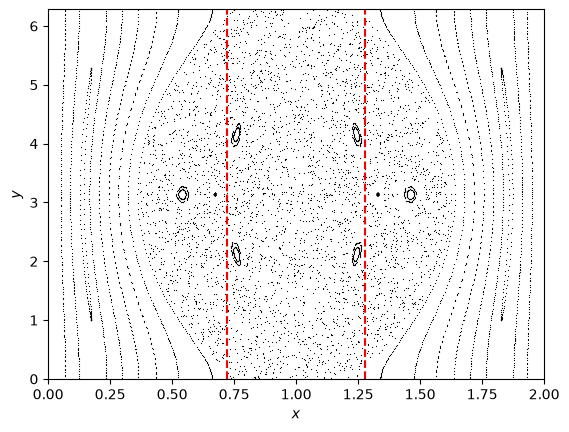

In [4]:
pplot = PoincarePlot.with_linspace(
    map,
    np.array([0.05, np.pi]),
    np.array([1.95, np.pi]),
    npts=50
)

# Follow each initial condition for 200 crossings
pplot.compute(npts=150)

# Plot directly in (x,y) coordinates
fig, ax = pplot.plot(plottype=None) # plottypeNone to directly plot in the coordinates of the map

ax.set_xlabel(r"$x$")
ax.set_ylabel(r"$y$")
ax.set_xlim(0, 2)
ax.set_ylim(0, 2*np.pi)

ax.axvline(
    xs1,
    linestyle="--",
    label=rf"$x_s1={xs1:.3f}$",
    color="r"
)
ax.axvline(
    xs2,
    linestyle="--",
    label=rf"$x_s2={xs2:.3f}$",
    color="r"
)
plt.show()

#### Find fixed points:

(<Figure size 640x480 with 1 Axes>, <Axes: >)

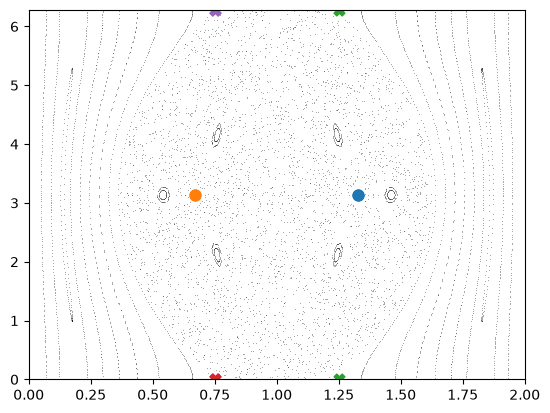

In [13]:
fig, ax = pplot.plot(s=0.5, xlim=[0, 2], ylim=[0, 2*np.pi], plottype=None)

fp = FixedPoint(map)

# Elliptic fixed points / O-points:
result = fp.find_with_iota(n = field.n1, m = field.m1, guess = np.array([xs1, 3]), method="scipy.root")   
fp.plot(fig=fig, ax=ax, s=60, plottype=None)

result = fp.find_with_iota(n = field.n2, m = field.m2, guess = np.array([xs2, 3]), method="scipy.root")   
fp.plot(fig=fig, ax=ax, s=60, plottype=None)

# Hyperbolic fixed points / X-points:
result = fp.find_with_iota(n = field.n1, m = field.m1, guess = np.array([xs1, 0.01]), method="scipy.root")   
fp.plot(fig=fig, ax=ax, s=60, plottype=None)

result = fp.find_with_iota(n = field.n2, m = field.m2, guess = np.array([xs2, 0.01]), method="scipy.root")   
fp.plot(fig=fig, ax=ax, s=60, plottype=None)

result = fp.find_with_iota(n = field.n2, m = field.m2, guess = np.array([xs2, 6.24]), method="scipy.root")   
fp.plot(fig=fig, ax=ax, s=60, plottype=None)

# # FP in the chaotic region:
# result = fp.find(
#     t = 1,
#     guess = np.array([1., np.pi]),
#     method="scipy.root"
# )   
# fp.plot(fig=fig, ax=ax, s=60, plottype=None)

# result = fp.find(
#     t = 1,
#     guess = np.array([1., 6.]),
#     method="scipy.root"
# )   
# fp.plot(fig=fig, ax=ax, s=60, plottype=None)

#### Find manifolds

In [18]:
fp2 = FixedPoint(map)
fp2.find_with_iota(n = field.n1, m = field.m1, guess = np.array([xs1, 0.01]), method="scipy.root")   

fp1 = FixedPoint(map)
fp1.find_with_iota(n = field.n1, m = field.m1, guess = np.array(fp2.coords[1]), method="scipy.root")  

fp3 = FixedPoint(map)
fp3.find_with_iota(n = field.n2, m = field.m2, guess = np.array([xs2, 0.1]), method="scipy.root")  

fp4 = FixedPoint(map)
fp4.find_with_iota(n = field.n2, m = field.m2, guess = np.array([xs2, 6.24]), method="scipy.root")  

ofp1 = FixedPoint(map)
ofp1.find_with_iota(n = field.n1, m = field.m1, guess = np.array([xs1, 3]), method="scipy.root")

ofp2 = FixedPoint(map)
ofp2.find_with_iota(n = field.n2, m = field.m2, guess = np.array([xs2, 3]), method="scipy.root")

In [21]:
manifold1 = Manifold(
    map, fp1, fp2,
    dir1=ofp1.coords[0] - fp1.coords[0],
    dir2=ofp1.coords[0] - fp2.coords[0]
)
manifold1.vector_s = np.real_if_close(manifold1.vector_s)
manifold1.vector_u = np.real_if_close(manifold1.vector_u)

manifold2 = Manifold(
    map, fp1, fp2,
    dir1=ofp1.coords[0] - fp1.coords[0],
    dir2=ofp1.coords[0] - fp2.coords[0],
    first_stable=False
)
manifold2.vector_s = np.real_if_close(manifold2.vector_s)
manifold2.vector_u = np.real_if_close(manifold2.vector_u)

manifold3 = Manifold(
    map, fp3, fp4,
    dir1=ofp2.coords[0] - fp3.coords[0],
    dir2=ofp2.coords[0] - fp4.coords[0]
)
manifold3.vector_s = np.real_if_close(manifold3.vector_s)
manifold3.vector_u = np.real_if_close(manifold3.vector_u)

manifold4 = Manifold(
    map, fp3, fp4,
    dir1=ofp2.coords[0] - fp3.coords[0],
    dir2=ofp2.coords[0] - fp4.coords[0],
    first_stable=False
)
manifold4.vector_s = np.real_if_close(manifold4.vector_s)
manifold4.vector_u = np.real_if_close(manifold4.vector_u)

In [ ]:
manifold1.find_clinics_exhaustive(first_guess_eps_s=1e-6, first_guess_eps_u=1e-6, ERR=1.3e-3)
stable1, unstable1 = manifold1.compute_adaptive2(tol=3e-3, n_u_extra=0, n_s_extra=0)
    
manifold2.find_clinics_exhaustive(first_guess_eps_s=1e-6, first_guess_eps_u=1e-6, ERR=1.3e-3)
stable2, unstable2 = manifold2.compute_adaptive2(tol=3e-3, n_u_extra=0, n_s_extra=0)

manifold3.find_clinics_exhaustive(first_guess_eps_s=1e-6, first_guess_eps_u=1e-6, ERR=1.3e-3)
stable3, unstable3 = manifold3.compute_adaptive2(tol=3e-3, n_u_extra=0, n_s_extra=0)

manifold4.find_clinics_exhaustive(first_guess_eps_s=1e-6, first_guess_eps_u=1e-6, ERR=1.3e-3)
stable4, unstable4 = manifold4.compute_adaptive2(tol=3e-3, n_u_extra=0, n_s_extra=0)

Shifted clinic by (-1, -1) iterations to the fundamental domain.
Homo/heteroclinic recorded and ordered.
Shifted clinic by (-1, -2) iterations to the fundamental domain.
Homo/heteroclinic recorded and ordered.
Shifted clinic by (0, -2) iterations to the fundamental domain.
Homo/heteroclinic already recorded, total clinics = 3. skipping...
Shifted clinic by (-1, 1) iterations to the fundamental domain.
Homo/heteroclinic recorded and ordered.
Shifted clinic by (-1, -1) iterations to the fundamental domain.
Homo/heteroclinic recorded and ordered.
Failed to refine clinic at eps_s=3.3827934792933786e-07, eps_u=6.38464463484545e-08: Root finding did not converge without expensive solve, cannot find clinic point. Consider trying with expensive=True to perform a more global search around the initial guess.
Failed to refine clinic at eps_s=6.651085226459976e-07, eps_u=5.430086636120569e-08: Root finding did not converge without expensive solve, cannot find clinic point. Consider trying with exp

In [12]:
stable_unwrapped1 = stable1.copy()
unstable_unwrapped1 = unstable1.copy()
stable_unwrapped1[:, 1] = np.unwrap(stable1[:, 1], period=2*np.pi)
unstable_unwrapped1[:, 1] = np.unwrap(unstable1[:, 1], period=2*np.pi)

stable_unwrapped2 = stable2.copy()
unstable_unwrapped2 = unstable2.copy()
stable_unwrapped2[:, 1] = np.unwrap(stable2[:, 1], period=2*np.pi)
unstable_unwrapped2[:, 1] = np.unwrap(unstable2[:, 1], period=2*np.pi)

stable_unwrapped3 = stable3.copy()
unstable_unwrapped3 = unstable3.copy()
stable_unwrapped3[:, 1] = np.unwrap(stable3[:, 1], period=2*np.pi)
unstable_unwrapped3[:, 1] = np.unwrap(unstable3[:, 1], period=2*np.pi)

stable_unwrapped4 = stable4.copy()
unstable_unwrapped4 = unstable4.copy()
stable_unwrapped4[:, 1] = np.unwrap(stable4[:, 1], period=2*np.pi)
unstable_unwrapped4[:, 1] = np.unwrap(unstable4[:, 1], period=2*np.pi)

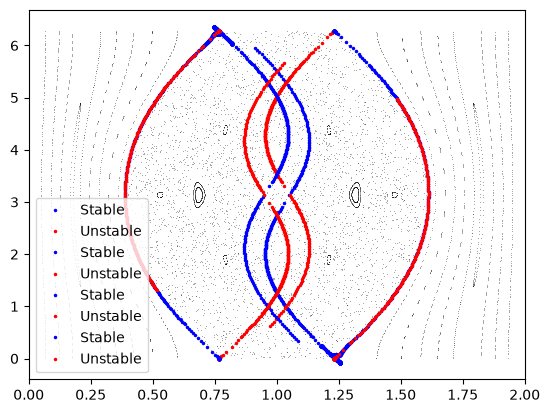

In [27]:
fig, ax = pplot.plot(marker=".", s=0.5, xlim=[.0, 2.], plottype=None)

ax.plot(stable_unwrapped1[:260, 0], stable_unwrapped1[:260, 1], color="blue", label="Stable", marker=".", markersize=3, linestyle="")
ax.plot(unstable_unwrapped1[:260, 0], unstable_unwrapped1[:260, 1], color="red", label="Unstable", marker=".", markersize=3, linestyle="")

ax.plot(stable_unwrapped2[:, 0], stable_unwrapped2[:, 1], color="blue", label="Stable", marker=".", markersize=3, linestyle="")
ax.plot(unstable_unwrapped2[:, 0], unstable_unwrapped2[:, 1], color="red", label="Unstable", marker=".", markersize=3, linestyle="")

ax.plot(stable_unwrapped4[:260, 0], stable_unwrapped4[:260, 1], color="blue", label="Stable", marker=".", markersize=3, linestyle="")
ax.plot(unstable_unwrapped4[:260, 0], unstable_unwrapped4[:260, 1], color="red", label="Unstable", marker=".", markersize=3, linestyle="")

ax.plot(stable_unwrapped3[:, 0], stable_unwrapped3[:, 1], color="blue", label="Stable", marker=".", markersize=3, linestyle="")
ax.plot(unstable_unwrapped3[:, 0], unstable_unwrapped3[:, 1], color="red", label="Unstable", marker=".", markersize=3, linestyle="")

ax.legend()
plt.show()